# 02 — Régression linéaire / Ridge implémentée from scratch

Code du modèle : `src/scratch_linear.py` (NumPy uniquement).

## Formulation mathématique
Pour l'observation $i$ (un pays-année), $\mathbf{x}_i\in\mathbb{R}^{p}$ ($p=11$ variables standardisées) :
$$\hat y_i = \mathbf{w}^\top\mathbf{x}_i + b$$

**Fonction objectif** (MSE + pénalité L2, le biais n'est pas pénalisé) :
$$J(\mathbf{w},b)=\frac{1}{2n}\sum_{i=1}^{n}\left(\mathbf{w}^\top\mathbf{x}_i+b-y_i\right)^2+\frac{\alpha}{2}\lVert\mathbf{w}\rVert^2$$

**Gradient** ($\mathbf{r}=X\mathbf{w}+b\mathbf{1}-\mathbf{y}$) :
$$\nabla_{\mathbf{w}}J=\frac1n X^\top\mathbf{r}+\alpha\mathbf{w},\qquad \frac{\partial J}{\partial b}=\frac1n\mathbf{1}^\top\mathbf{r}$$

**Optimisation.**
* *Descente de gradient* : $\theta_{k+1}=\theta_k-\eta\nabla J(\theta_k)$. $J$ est convexe et quadratique de hessienne $H=\tilde X^\top\tilde X/n+\alpha D$ ; la DG converge si et seulement si $0<\eta<2/\lambda_{\max}(H)$. Arrêt : $|J_k-J_{k-1}|<10^{-10}$ ou nombre maximal d'itérations.
* *SGD mini-lots* : gradient estimé sur $B$ observations tirées sans remise, pas décroissant $\eta_e=\eta_0/(1+\delta e)$.
* *Équations normales* (vérification) : $\nabla J=0 \iff (\tilde X^\top\tilde X/n+\alpha D)\,\theta=\tilde X^\top\mathbf{y}/n$, résolu exactement.

**Pourquoi ce modèle ?** La question porte sur *l'influence* des catastrophes : un modèle linéaire fournit des coefficients directement interprétables (points de croissance perdus par unité de choc), avec intervalles de confiance. L'arbre du notebook 03 relâche ensuite l'hypothèse de linéarité.

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # métriques autorisées
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
from src.scratch_linear import LinearRegressionScratch, numerical_gradient_check, max_stable_lr, cluster_bootstrap_coefs
panel = dp.build_panel()
s = dp.make_splits(panel)
F = s.features
print({k: len(v) for k, v in s.frames.items()})

{'train': 5174, 'val': 1359, 'test': 1371, 'stress': 189}


## 1. Vérifications numériques
### 1.1 Gradient analytique vs différences finies centrées

In [2]:
for a in [0.0, 0.1, 1.0]:
    err = numerical_gradient_check(LinearRegressionScratch(alpha=a), s.X_train[:500], s.y_train[:500])
    print(f"alpha={a:<4}  erreur relative = {err:.2e}")

alpha=0.0   erreur relative = 4.45e-10
alpha=0.1   erreur relative = 4.69e-10
alpha=1.0   erreur relative = 3.98e-10


Erreur relative ≈ 1e-10 : le gradient implémenté est correct.

### 1.2 Pas d'apprentissage et convergence

lambda_max(H) = 2.464  ->  pas maximal théorique 2/lambda_max = 0.812


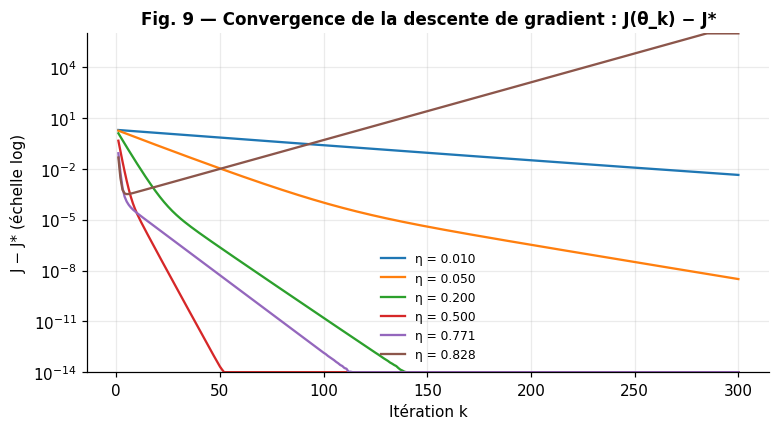

In [3]:
lr_max = max_stable_lr(s.X_train)
print(f"lambda_max(H) = {2/lr_max:.3f}  ->  pas maximal théorique 2/lambda_max = {lr_max:.3f}")
J_star = LinearRegressionScratch(solver="normal").fit(s.X_train, s.y_train).loss(s.X_train, s.y_train)
fig, ax = plt.subplots(figsize=(8, 4))
for lr in [0.01, 0.05, 0.2, 0.5, 0.95 * lr_max, 1.02 * lr_max]:
    m = LinearRegressionScratch(solver="gd", lr=lr, n_iter=300, tol=0)
    with np.errstate(all="ignore"):
        try:
            m.fit(s.X_train, s.y_train); lab = f"η = {lr:.3f}"
        except FloatingPointError:
            lab = f"η = {lr:.3f} (diverge)"
    h = np.array(m.loss_history_) - J_star
    ax.semilogy(np.arange(1, len(h) + 1), np.clip(h, 1e-14, 1e6), label=lab)
ax.set(title="Fig. 9 — Convergence de la descente de gradient : J(θ_k) − J*", xlabel="Itération k", ylabel="J − J* (échelle log)", ylim=(1e-14, 1e6))
ax.legend(fontsize=8)
save(fig, "fig09_gd_convergence.png"); plt.show()

La convergence est **linéaire** (droite en échelle log), d'autant plus rapide que $\eta$ s'approche de $1/\lambda_{\max}$ ; au-delà de $2/\lambda_{\max}$ l'algorithme diverge, exactement comme le prédit la théorie. Le conditionnement est bon car les variables sont standardisées (sans standardisation, $\lambda_{\max}$ exploserait à cause du log PIB/hab).

### 1.3 Trois solveurs, une même solution

In [4]:
models = {
    "Équations normales": LinearRegressionScratch(solver="normal"),
    "Descente de gradient": LinearRegressionScratch(solver="gd", lr=0.5, n_iter=10000, tol=1e-14),
    "SGD (B=64)": LinearRegressionScratch(solver="sgd", lr=0.05, n_iter=60, batch_size=64, decay=0.05),
}
coefs = {}
for name, m in models.items():
    t = time.perf_counter(); m.fit(s.X_train, s.y_train); dt = time.perf_counter() - t
    coefs[name] = np.append(m.intercept_, m.coef_)
    print(f"{name:22s} itérations/époques = {m.n_iter_:5d}   temps = {dt*1e3:7.1f} ms   J = {m.loss(s.X_train, s.y_train):.6f}")
C = pd.DataFrame(coefs, index=["biais"] + F)
print("max |GD - normal|  =", np.abs(C.iloc[:, 1] - C.iloc[:, 0]).max())
print("max |SGD - normal| =", np.abs(C.iloc[:, 2] - C.iloc[:, 0]).max())
C

Équations normales     itérations/époques =     0   temps =     0.6 ms   J = 11.842209
Descente de gradient   itérations/époques =    51   temps =     5.8 ms   J = 11.842209
SGD (B=64)             itérations/époques =    60   temps =   148.9 ms   J = 11.843165
max |GD - normal|  = 1.7222742878728048e-07
max |SGD - normal| = 0.017198055757382757


,Équations normales,Descente de gradient,SGD (B=64)
biais,3.755,3.755,3.743
log_dmg_climate_pct,-0.263,-0.263,-0.280
log_dmg_climate_pct_lag1,0.131,0.131,0.149
log_deaths_climate_pm,-0.097,-0.097,-0.108
log_affected_climate_pct,-0.031,-0.031,-0.038
n_hydro,0.230,0.230,0.229
n_meteo,0.077,0.077,0.062
n_climato,-0.036,-0.036,-0.033
log_dmg_geo_pct,-0.093,-0.093,-0.099
growth_lag1,1.809,1.809,1.797


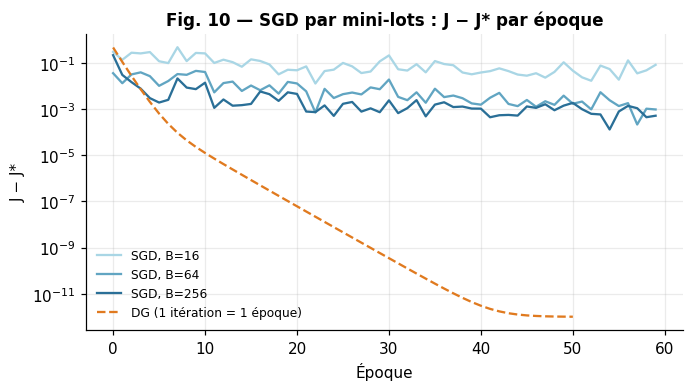

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for B, c in [(16, "#a9d6e5"), (64, "#61a5c2"), (256, "#2a6f97")]:
    m = LinearRegressionScratch(solver="sgd", lr=0.05, n_iter=60, batch_size=B, decay=0.05).fit(s.X_train, s.y_train)
    ax.semilogy(np.array(m.loss_history_) - J_star + 1e-12, color=c, label=f"SGD, B={B}")
ax.semilogy(np.array(models["Descente de gradient"].loss_history_[:60]) - J_star + 1e-12, color=C_SKLEARN, ls="--", label="DG (1 itération = 1 époque)")
ax.set(title="Fig. 10 — SGD par mini-lots : J − J* par époque", xlabel="Époque", ylabel="J − J*")
ax.legend(fontsize=8); save(fig, "fig10_sgd.png"); plt.show()

La SGD atteint en quelques époques une précision de l'ordre de $10^{-3}$–$10^{-4}$ puis plafonne (bruit du gradient stochastique, que la décroissance du pas réduit lentement) ; la DG complète atteint la précision machine. Sur $n\approx5\,000$ la DG suffit largement ; la SGD deviendrait intéressante pour des millions d'observations.

## 2. Choix de la régularisation α (sur la validation)

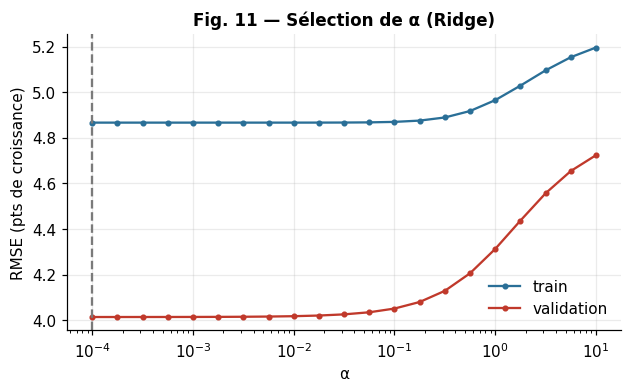

alpha retenu = 0


In [6]:
alphas = np.r_[0, np.logspace(-4, 1, 21)]
rows = []
for a in alphas:
    m = LinearRegressionScratch(solver="normal", alpha=a).fit(s.X_train, s.y_train)
    rows.append((a, mean_squared_error(s.y_train, m.predict(s.X_train)) ** .5,
                 mean_squared_error(s.y_val, m.predict(s.X_val)) ** .5))
ridge = pd.DataFrame(rows, columns=["alpha", "rmse_train", "rmse_val"])
best_alpha = ridge.loc[ridge.rmse_val.idxmin(), "alpha"]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.semilogx(ridge.alpha[1:], ridge.rmse_train[1:], "o-", ms=3, label="train", color=C_SCRATCH)
ax.semilogx(ridge.alpha[1:], ridge.rmse_val[1:], "o-", ms=3, label="validation", color=C_ACCENT)
ax.axvline(max(best_alpha, 1e-4), color=C_NEUTRAL, ls="--")
ax.set(title="Fig. 11 — Sélection de α (Ridge)", xlabel="α", ylabel="RMSE (pts de croissance)"); ax.legend()
save(fig, "fig11_ridge_alpha.png"); plt.show()
print(f"alpha retenu = {best_alpha:.4g}")

## 3. Modèle final : performances et références naïves

In [7]:
lin = LinearRegressionScratch(solver="gd", alpha=best_alpha, lr=0.5, n_iter=10000, tol=1e-14).fit(s.X_train, s.y_train)
lag = F.index("growth_lag1")
def unstd_lag(X): return X[:, lag] * s.std[lag] + s.mean[lag]
def metrics(y, p): return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))
rows = []
for split in ["train", "val", "test", "stress"]:
    X, y = getattr(s, f"X_{split}"), getattr(s, f"y_{split}")
    rows.append({"split": split, "modèle": "Moyenne du train", **metrics(y, np.full_like(y, s.y_train.mean()))})
    rows.append({"split": split, "modèle": "Persistance (ŷ_t = y_{t-1})", **metrics(y, unstd_lag(X))})
    rows.append({"split": split, "modèle": "Linéaire from scratch", **metrics(y, lin.predict(X))})
perf = pd.DataFrame(rows).set_index(["split", "modèle"])
perf.to_csv("../results/linear_performance.csv"); perf

MAE   RMSE         R2
split  modèle                                              
train  Moyenne du train             3.719  5.266  0.000e+00
       Persistance (ŷ_t = y_{t-1})  4.023  6.069 -3.283e-01
       Linéaire from scratch        3.348  4.867  1.459e-01
val    Moyenne du train             3.553  4.835 -6.863e-05
       Persistance (ŷ_t = y_{t-1})  3.463  5.103 -1.142e-01
       Linéaire from scratch        2.818  4.014  3.107e-01
test   Moyenne du train             2.531  3.671 -3.905e-02
       Persistance (ŷ_t = y_{t-1})  2.180  3.775 -9.888e-02
       Linéaire from scratch        1.973  3.130  2.443e-01
stress Moyenne du train             8.357  9.657 -2.192e+00
       Persistance (ŷ_t = y_{t-1})  7.538  8.818 -1.661e+00
       Linéaire from scratch        5.241  6.653 -5.149e-01

## 4. L'apport des catastrophes : étude d'ablation
On compare, à protocole identique, un modèle **contrôles seuls** (inertie, niveau de développement, cycle mondial) et le modèle **contrôles + catastrophes**. Une baisse de l'erreur hors échantillon mesure l'information *prédictive* apportée par les chocs climatiques. On regarde aussi le sous-échantillon des pays-années réellement frappés (dommages > 0,1 % du PIB), où l'effet doit se concentrer.

In [8]:
ctrl = [F.index(f) for f in dp.CONTROL_FEATURES]
m_ctrl = LinearRegressionScratch(solver="normal", alpha=best_alpha).fit(s.X_train[:, ctrl], s.y_train)
rows = []
for split in ["val", "test"]:
    X, y, fr = getattr(s, f"X_{split}"), getattr(s, f"y_{split}"), s.frames[split]
    hit = (fr.dmg_climate_pct > 0.1).to_numpy()
    for name, pred in [("contrôles seuls", m_ctrl.predict(X[:, ctrl])), ("contrôles + catastrophes", lin.predict(X))]:
        rows.append({"split": split, "modèle": name, "RMSE (tous)": mean_squared_error(y, pred) ** .5,
                     "R2 (tous)": r2_score(y, pred), f"RMSE (frappés)": mean_squared_error(y[hit], pred[hit]) ** .5,
                     "n frappés": hit.sum()})
abl = pd.DataFrame(rows).set_index(["split", "modèle"])
abl.to_csv("../results/linear_ablation.csv"); abl

RMSE (tous)  R2 (tous)  RMSE (frappés)  \
split modèle                                                             
val   contrôles seuls                 4.052      0.298           3.191   
      contrôles + catastrophes        4.014      0.311           2.999   
test  contrôles seuls                 3.157      0.232           3.080   
      contrôles + catastrophes        3.130      0.244           2.807   

                                n frappés  
split modèle                               
val   contrôles seuls                 145  
      contrôles + catastrophes        145  
test  contrôles seuls                 152  
      contrôles + catastrophes        152

## 5. Interprétation des coefficients et incertitude

Les coefficients appris sur variables standardisées sont reconvertis dans l'unité d'origine ($\beta_j=w_j/\sigma_j$). L'incertitude est estimée par un **bootstrap par pays** (500 rééchantillonnages de pays entiers, implémenté from scratch) : il respecte la dépendance temporelle intra-pays, que les erreurs standard OLS classiques ignoreraient.

In [9]:
groups = s.frames["train"].ISO.to_numpy()
B = cluster_bootstrap_coefs(s.X_train, s.y_train, groups, alpha=best_alpha, n_boot=500, seed=SEED)
coef = pd.DataFrame({
    "beta (unité d'origine)": lin.coef_ / s.std,
    "IC95 bas": np.percentile(B, 2.5, axis=0) / s.std,
    "IC95 haut": np.percentile(B, 97.5, axis=0) / s.std,
    "w standardisé": lin.coef_,
}, index=F)
coef["significatif"] = (coef["IC95 bas"] > 0) | (coef["IC95 haut"] < 0)
coef.to_csv("../results/linear_coefficients.csv"); coef

,beta (unité d'origine),IC95 bas,IC95 haut,w standardisé,significatif
log_dmg_climate_pct,-0.644,-1.051,-0.261,-0.263,True
log_dmg_climate_pct_lag1,0.316,0.002,0.649,0.131,True
log_deaths_climate_pm,-0.109,-0.305,0.082,-0.097,False
log_affected_climate_pct,-0.044,-0.273,0.174,-0.031,False
n_hydro,0.187,0.036,0.316,0.230,True
n_meteo,0.054,-0.017,0.234,0.077,False
n_climato,-0.084,-0.438,0.271,-0.036,False
log_dmg_geo_pct,-0.531,-1.130,0.114,-0.093,False
growth_lag1,0.336,0.282,0.389,1.809,True
log_gdppc_lag1,-0.166,-0.270,-0.048,-0.256,True


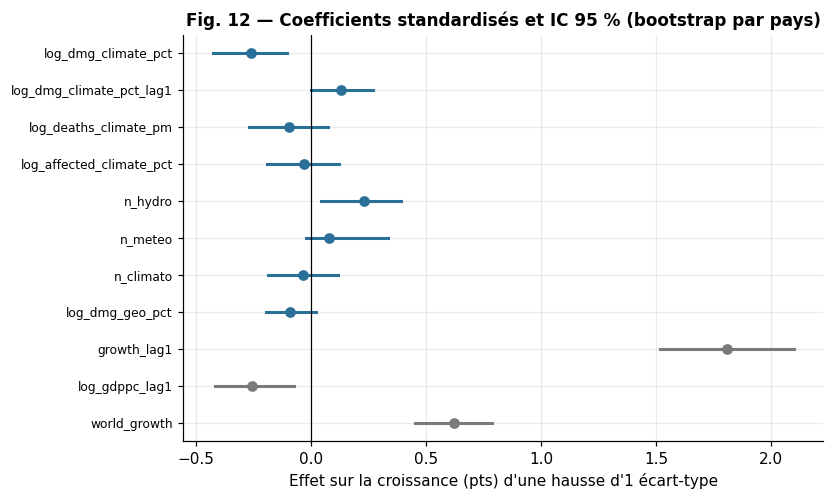

In [10]:
lo = np.percentile(B, 2.5, axis=0); hi = np.percentile(B, 97.5, axis=0)
order = np.arange(len(F))[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
colors = [C_CLIMATE if f in dp.DISASTER_FEATURES else C_NEUTRAL for f in F]
for k, j in enumerate(order):
    ax.plot([lo[j], hi[j]], [k, k], color=colors[j], lw=2)
    ax.plot(lin.coef_[j], k, "o", color=colors[j])
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(F))); ax.set_yticklabels([F[j] for j in order], fontsize=8)
ax.set(title="Fig. 12 — Coefficients standardisés et IC 95 % (bootstrap par pays)",
       xlabel="Effet sur la croissance (pts) d'une hausse d'1 écart-type")
save(fig, "fig12_coefficients.png"); plt.show()

In [11]:
j0, j1 = F.index("log_dmg_climate_pct"), F.index("log_dmg_climate_pct_lag1")
b0, b1 = lin.coef_[j0] / s.std[j0], lin.coef_[j1] / s.std[j1]
B0, B1 = B[:, j0] / s.std[j0], B[:, j1] / s.std[j1]
rows = []
for d in [0.5, 1, 5, 10, 50]:
    x = np.log1p(d)
    rows.append({"dommages (% PIB)": d, "effet année t (pts)": b0 * x,
                 "IC95 t": f"[{np.percentile(B0*x,2.5):.2f} ; {np.percentile(B0*x,97.5):.2f}]",
                 "effet t+1 (pts)": b1 * x, "effet cumulé t, t+1": (b0 + b1) * x,
                 "IC95 cumulé": f"[{np.percentile((B0+B1)*x,2.5):.2f} ; {np.percentile((B0+B1)*x,97.5):.2f}]"})
eff = pd.DataFrame(rows); eff.to_csv("../results/linear_effects.csv", index=False); eff

,dommages (% PIB),effet année t (pts),IC95 t,effet t+1 (pts),"effet cumulé t, t+1",IC95 cumulé
0,0.5,-0.261,[-0.43 ; -0.11],0.128,-0.133,[-0.30 ; 0.04]
1,1.0,-0.447,[-0.73 ; -0.18],0.219,-0.228,[-0.52 ; 0.06]
2,5.0,-1.155,[-1.88 ; -0.47],0.566,-0.589,[-1.35 ; 0.16]
3,10.0,-1.545,[-2.52 ; -0.63],0.757,-0.788,[-1.80 ; 0.22]
4,50.0,-2.534,[-4.13 ; -1.03],1.242,-1.293,[-2.95 ; 0.35]


**Lecture.** Un choc climatique causant des dommages égaux à 10 % du PIB est associé, toutes choses égales par ailleurs, à une croissance plus faible d'environ 1,5 point l'année du choc, suivie d'un rebond partiel l'année suivante (reconstruction). L'effet cumulé sur deux ans reste négatif mais plus incertain. Les variables de *comptage* (nombre d'inondations, de tempêtes) ont des coefficients faibles ou positifs : elles mesurent plutôt la taille du pays et la qualité de l'enregistrement que l'intensité du choc.

## 6. Diagnostic des résidus

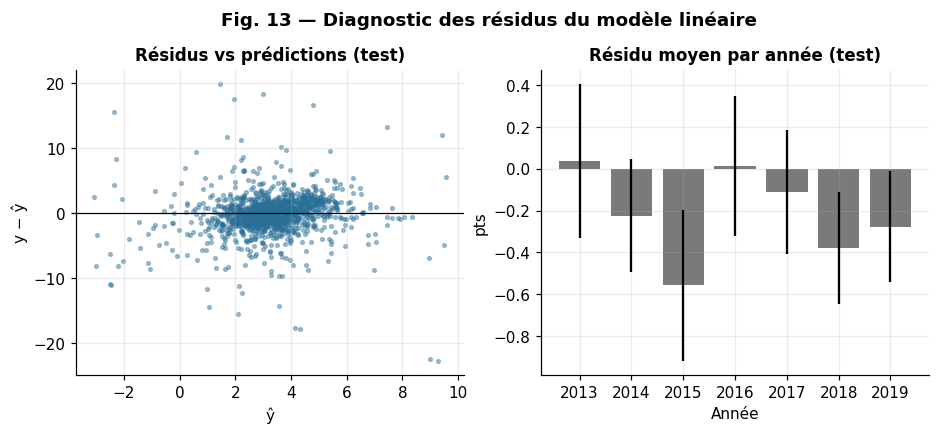

In [12]:
pred = lin.predict(s.X_test); res = s.y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(pred, res, s=6, alpha=0.4, color=C_SCRATCH); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(title="Résidus vs prédictions (test)", xlabel="ŷ", ylabel="y − ŷ")
yr = s.frames["test"].assign(res=res).groupby("year").res.agg(["mean", "std"])
axes[1].bar(yr.index, yr["mean"], yerr=yr["std"] / 10, color=C_NEUTRAL)
axes[1].set(title="Résidu moyen par année (test)", xlabel="Année", ylabel="pts")
fig.suptitle("Fig. 13 — Diagnostic des résidus du modèle linéaire", fontweight="bold", y=1.03)
save(fig, "fig13_residuals.png"); plt.show()

Les résidus sont centrés mais **hétéroscédastiques** : la variance est bien plus forte pour les économies volatiles (petits pays, exportateurs de matières premières). Le modèle sous-estime les récessions profondes, qui viennent surtout de chocs non climatiques (crises financières, conflits, prix du pétrole).